In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

In [2]:
# Install the necessary libraries
!pip install -q transformers datasets evaluate accelerate matplotlib scikit-learn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 4.4 MB/s eta 0:00:00


In [3]:
import pandas as pd
import urllib.request
import tarfile
from datasets import Dataset, DatasetDict
from transformers import AutoTokenizer, AutoModelForSequenceClassification, TrainingArguments, Trainer
import evaluate

# 1. Download and extract the raw dataset
url = "https://dl.fbaipublicfiles.com/parlai/empatheticdialogues/empatheticdialogues.tar.gz"
print("Downloading dataset...")
urllib.request.urlretrieve(url, "empatheticdialogues.tar.gz")

print("Extracting files...")
with tarfile.open("empatheticdialogues.tar.gz", "r:gz") as tar:
    tar.extractall()

# 2. Load the CSVs with pandas, explicitly telling it to skip any messy rows
print("Cleaning and loading data...")
df_train = pd.read_csv("empatheticdialogues/train.csv", on_bad_lines="skip")
df_valid = pd.read_csv("empatheticdialogues/valid.csv", on_bad_lines="skip")
df_test = pd.read_csv("empatheticdialogues/test.csv", on_bad_lines="skip")

# 3. Convert the clean pandas tables back into the Hugging Face dictionary format
dataset = DatasetDict({
    "train": Dataset.from_pandas(df_train),
    "validation": Dataset.from_pandas(df_valid),
    "test": Dataset.from_pandas(df_test)
})

# 4. View the first 5 rows!
print("Dataset loaded successfully!")
display_data = dataset['train'].to_pandas()
display(display_data.head(5))

Extracting files...


/tmp/ipykernel_55/2082806120.py:15: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  tar.extractall()


Cleaning and loading data...
Dataset loaded successfully!


,conv_id,utterance_idx,context,prompt,speaker_idx,utterance,selfeval,tags
0,hit:0_conv:1,1,sentimental,I remember going to the fireworks with my best...,1,I remember going to see the fireworks with my ...,5|5|5_2|2|5,None
1,hit:0_conv:1,2,sentimental,I remember going to the fireworks with my best...,0,Was this a friend you were in love with_comma_...,5|5|5_2|2|5,None
2,hit:0_conv:1,3,sentimental,I remember going to the fireworks with my best...,1,This was a best friend. I miss her.,5|5|5_2|2|5,None
3,hit:0_conv:1,4,sentimental,I remember going to the fireworks with my best...,0,Where has she gone?,5|5|5_2|2|5,None
4,hit:0_conv:1,5,sentimental,I remember going to the fireworks with my best...,1,We no longer talk.,5|5|5_2|2|5,None


In [4]:
dataset.shape

{'train': (76668, 8), 'validation': (6318, 8), 'test': (5701, 8)}

In [5]:
display_data["context"].unique()

array(['sentimental', 'afraid', 'proud', 'faithful', 'terrified',
       'joyful', 'angry', 'sad', 'jealous', 'grateful', 'prepared',
       'embarrassed', 'excited', 'annoyed', 'lonely', 'ashamed', 'guilty',
       'surprised', 'nostalgic', 'confident', 'furious', 'disappointed',
       'caring', 'trusting', 'disgusted', 'anticipating', 'anxious',
       'hopeful', 'content', 'impressed', 'apprehensive', 'devastated'],
      dtype=object)

In [6]:
display_data["context"].value_counts()

context
surprised       3956
excited         2935
angry           2740
proud           2719
annoyed         2642
sad             2634
afraid          2510
lonely          2503
grateful        2487
terrified       2487
guilty          2463
anxious         2456
disgusted       2447
confident       2440
anticipating    2439
hopeful         2404
furious         2394
impressed       2381
disappointed    2356
nostalgic       2350
joyful          2346
jealous         2329
prepared        2292
content         2214
devastated      2192
embarrassed     2191
sentimental     2073
caring          2054
trusting        2001
ashamed         1976
apprehensive    1822
faithful        1435
Name: count, dtype: int64

In [7]:
# ==========================================
# PART 2: DEFINE THE 7 BUCKETS
# ==========================================
emotion_mapping = {
    "angry": "Anger", "furious": "Anger", "annoyed": "Anger", "disgusted": "Anger", "jealous": "Anger",
    "afraid": "Fear & Tension", "terrified": "Fear & Tension", "anxious": "Fear & Tension", "apprehensive": "Fear & Tension",
    "sad": "Sadness", "lonely": "Sadness", "devastated": "Sadness", "disappointed": "Sadness",
    "excited": "Joy & Confidence", "proud": "Joy & Confidence", "grateful": "Joy & Confidence", "joyful": "Joy & Confidence", "content": "Joy & Confidence", "impressed": "Joy & Confidence", "hopeful": "Joy & Confidence", "confident": "Joy & Confidence",
    "caring": "Connection & Trust", "trusting": "Connection & Trust", "faithful": "Connection & Trust",
    "guilty": "Vulnerability", "embarrassed": "Vulnerability", "ashamed": "Vulnerability",
    "nostalgic": "Suspense & Reflection", "sentimental": "Suspense & Reflection", "surprised": "Suspense & Reflection", "anticipating": "Suspense & Reflection", "prepared": "Suspense & Reflection"
}

grouped_labels = list(set(emotion_mapping.values()))
new_label2id = {label: i for i, label in enumerate(grouped_labels)}
new_id2label = {i: label for i, label in enumerate(grouped_labels)}

# ==========================================
# PART 3: UPGRADED GPT-2 TOKENIZATION 
# ==========================================
tokenizer = AutoTokenizer.from_pretrained("gpt2")
tokenizer.pad_token = tokenizer.eos_token
tokenizer.padding_side = "left" 

def group_and_tokenize(examples):
    # THE FIX: Combine the background situation ('prompt') with the spoken words ('utterance')
    combined_text = [
        f"Situation: {str(p).replace('_comma_', ',')} Dialogue: {str(u).replace('_comma_', ',')}" 
        for p, u in zip(examples['prompt'], examples['utterance'])
    ]
    
    # We increase max_length slightly to accommodate the extra context
    encoding = tokenizer(combined_text, padding="max_length", truncation=True, max_length=160)
    
    new_label_strings = [emotion_mapping[emotion] for emotion in examples['context']]
    encoding['label'] = [new_label2id[label] for label in new_label_strings]
    return encoding

print("Tokenizing combined context data for GPT-2...")
gpt_encoded_dataset = dataset.map(group_and_tokenize, batched=True)
print("Done! Ready for upgraded training.")

config.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

Tokenizing combined context data for GPT-2...


Map:   0%|          | 0/76668 [00:00<?, ? examples/s]

Map:   0%|          | 0/6318 [00:00<?, ? examples/s]

Map:   0%|          | 0/5701 [00:00<?, ? examples/s]

Done! Ready for upgraded training.


In [8]:
from transformers import AutoModelForSequenceClassification, Trainer, TrainingArguments, EarlyStoppingCallback
import evaluate
import numpy as np

# 1. Load the model but add "Dropout" (The Anti-Memorization trick!)
model = AutoModelForSequenceClassification.from_pretrained(
    "gpt2",
    num_labels=len(grouped_labels),
    id2label=new_id2label,
    label2id=new_label2id,
    resid_pdrop=0.2,  # Force the AI to drop 20% of its memory while studying
    embd_pdrop=0.2,   # Drop 20% of the word embeddings
    attn_pdrop=0.2    # Drop 20% of its attention
)
model.config.pad_token_id = model.config.eos_token_id

accuracy_metric = evaluate.load("accuracy")

def compute_metrics(eval_pred):
    predictions, true_labels = eval_pred
    predictions = np.argmax(predictions, axis=1)
    return accuracy_metric.compute(predictions=predictions, references=true_labels)

# 2. The New "Strict" Training Rules
training_args = TrainingArguments(
    output_dir="./gpt2_healthy_vibe_model", 
    eval_strategy="epoch",         
    save_strategy="epoch",         
    learning_rate=3e-5,              # Slow down the learning a little bit
    lr_scheduler_type="cosine",      
    warmup_ratio=0.1,                
    per_device_train_batch_size=16,  
    per_device_eval_batch_size=16,
    gradient_accumulation_steps=2,   
    num_train_epochs=3,              # ONLY 3 Epochs! Don't give it time to memorize
    weight_decay=0.15,               # INCREASED! A heavy penalty for memorizing exact words
    logging_steps=100,             
    load_best_model_at_end=True,     
    metric_for_best_model="accuracy",
    greater_is_better=True,
    save_total_limit=1,              
    report_to="none"               
)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=gpt_encoded_dataset["train"],
    eval_dataset=gpt_encoded_dataset["validation"],
    processing_class=tokenizer,     
    compute_metrics=compute_metrics,
    callbacks=[EarlyStoppingCallback(early_stopping_patience=1)] 
)

print("Starting strictly regulated GPT-2 training...")
trainer.train()

model.safetensors:   0%|          | 0.00/548M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

GPT2ForSequenceClassification LOAD REPORT from: gpt2
Key          | Status  | 
-------------+---------+-
score.weight | MISSING | 

Notes:
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


warmup_ratio is deprecated and will be removed in v5.2. Use `warmup_steps` instead.


Starting strictly regulated GPT-2 training...


Epoch,Training Loss,Validation Loss,Accuracy
1,1.431740,0.703634,0.759734
2,0.968684,0.687806,0.771130
3,0.869520,0.713657,0.776986


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=7188, training_loss=1.4340797545316821, metrics={'train_runtime': 4133.5295, 'train_samples_per_second': 55.643, 'train_steps_per_second': 1.739, 'total_flos': 1.878187845648384e+16, 'train_loss': 1.4340797545316821, 'epoch': 3.0})

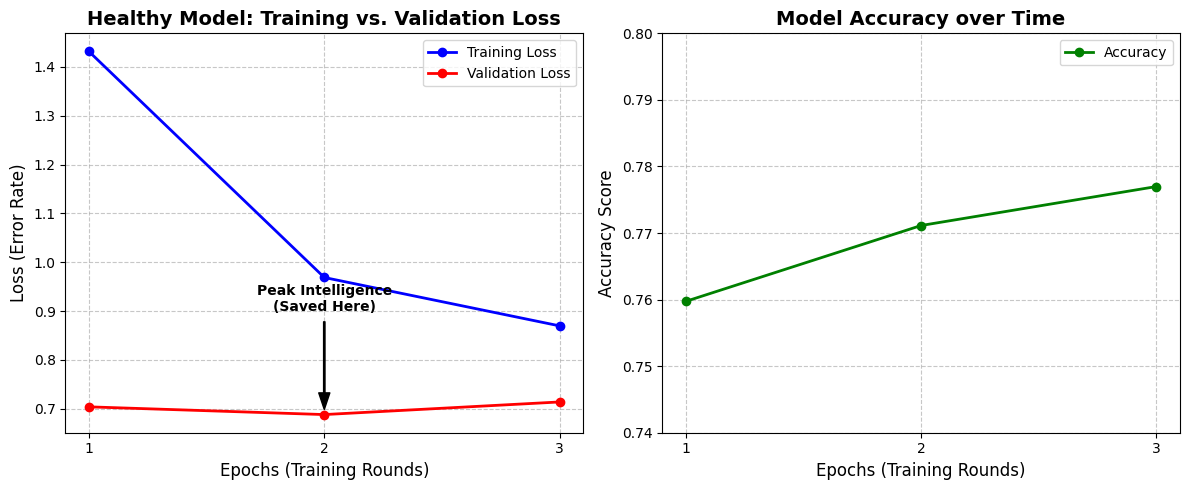

In [17]:
import matplotlib.pyplot as plt

# 1. The exact numbers from your healthy training logs
epochs = [1, 2, 3]
train_loss = [1.431740, 0.968684, 0.869520]
val_loss = [0.703634, 0.687806, 0.713657]
accuracy = [0.759734, 0.771130, 0.776986]

# 2. Set up a wide canvas for two side-by-side graphs
plt.figure(figsize=(12, 5))

# --- GRAPH 1: The Healthy Learning Curve (Loss) ---
plt.subplot(1, 2, 1)
plt.plot(epochs, train_loss, label='Training Loss', marker='o', color='blue', linewidth=2)
plt.plot(epochs, val_loss, label='Validation Loss', marker='o', color='red', linewidth=2)

# Point out the "Sweet Spot" at Epoch 2!
plt.annotate('Peak Intelligence\n(Saved Here)', xy=(2, 0.687806), xytext=(2, 0.9),
             arrowprops=dict(facecolor='black', shrink=0.05, width=1, headwidth=8),
             ha='center', fontsize=10, fontweight='bold')

plt.title('Healthy Model: Training vs. Validation Loss', fontsize=14, fontweight='bold')
plt.xlabel('Epochs (Training Rounds)', fontsize=12)
plt.ylabel('Loss (Error Rate)', fontsize=12)
plt.xticks(epochs) # Force x-axis to only show 1, 2, 3
plt.legend()
plt.grid(True, linestyle='--', alpha=0.7)

# --- GRAPH 2: The Rising Accuracy ---
plt.subplot(1, 2, 2)
plt.plot(epochs, accuracy, label='Accuracy', marker='o', color='green', linewidth=2)
plt.title('Model Accuracy over Time', fontsize=14, fontweight='bold')
plt.xlabel('Epochs (Training Rounds)', fontsize=12)
plt.ylabel('Accuracy Score', fontsize=12)
plt.xticks(epochs) # Force x-axis to only show 1, 2, 3
plt.ylim(0.74, 0.80) # Zoom in to see the growth clearly
plt.legend()
plt.grid(True, linestyle='--', alpha=0.7)

# 3. Show the beautiful graphs!
plt.tight_layout()
plt.show()

Loading your healthy AI brain from: ./gpt2_healthy_vibe_model/checkpoint-7188


Loading weights:   0%|          | 0/149 [00:00<?, ?it/s]


Testing the model on 500 general scenarios...


100%|██████████| 500/500 [00:04<00:00, 120.58it/s]



=== OFFICIAL CLASSIFICATION REPORT ===
                       precision    recall  f1-score   support

                Anger       0.77      0.80      0.79        87
   Connection & Trust       0.66      0.69      0.68        36
       Fear & Tension       0.86      0.89      0.87        54
     Joy & Confidence       0.79      0.87      0.82       122
              Sadness       0.76      0.77      0.77        70
Suspense & Reflection       0.84      0.66      0.74        89
        Vulnerability       0.79      0.74      0.77        42

             accuracy                           0.79       500
            macro avg       0.78      0.78      0.78       500
         weighted avg       0.79      0.79      0.78       500



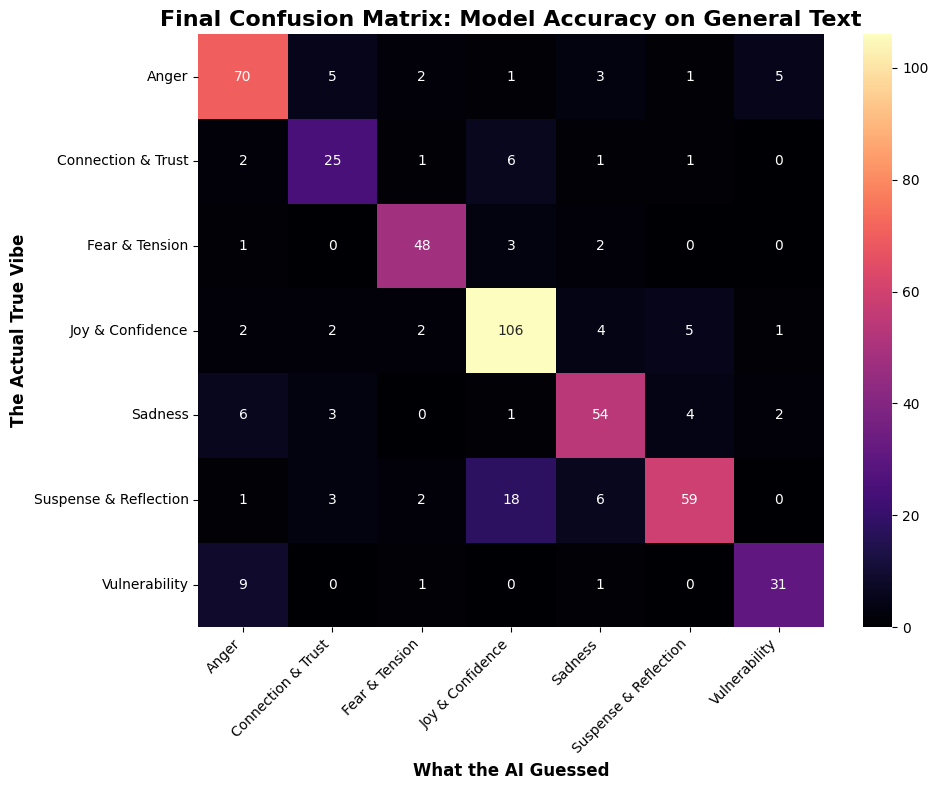

In [11]:
import pandas as pd
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
from transformers import pipeline
from tqdm import tqdm # This gives us a cool loading bar!
import os

# 1. Automatically find your newly trained, healthy model!
output_dir = "./gpt2_healthy_vibe_model"
checkpoints = [f for f in os.listdir(output_dir) if f.startswith("checkpoint")]
best_checkpoint = os.path.join(output_dir, sorted(checkpoints, key=lambda x: int(x.split("-")[-1]))[-1])

print(f"Loading your healthy AI brain from: {best_checkpoint}")
emotion_classifier = pipeline("text-classification", model=best_checkpoint, truncation=True, max_length=160)

# 2. Re-apply our 7 buckets to the test dataset
emotion_mapping = {
    "angry": "Anger", "furious": "Anger", "annoyed": "Anger", "disgusted": "Anger", "jealous": "Anger",
    "afraid": "Fear & Tension", "terrified": "Fear & Tension", "anxious": "Fear & Tension", "apprehensive": "Fear & Tension",
    "sad": "Sadness", "lonely": "Sadness", "devastated": "Sadness", "disappointed": "Sadness",
    "excited": "Joy & Confidence", "proud": "Joy & Confidence", "grateful": "Joy & Confidence", "joyful": "Joy & Confidence", "content": "Joy & Confidence", "impressed": "Joy & Confidence", "hopeful": "Joy & Confidence", "confident": "Joy & Confidence",
    "caring": "Connection & Trust", "trusting": "Connection & Trust", "faithful": "Connection & Trust",
    "guilty": "Vulnerability", "embarrassed": "Vulnerability", "ashamed": "Vulnerability",
    "nostalgic": "Suspense & Reflection", "sentimental": "Suspense & Reflection", "surprised": "Suspense & Reflection", "anticipating": "Suspense & Reflection", "prepared": "Suspense & Reflection"
}

# The test dataset is already loaded in your notebook's memory from earlier!
df_test = dataset['test'].to_pandas()
df_test['clean_label'] = df_test['context'].map(emotion_mapping)
df_test = df_test.dropna(subset=['clean_label']) 

# 3. Format the text with our secret Situation + Dialogue trick
df_test['combined_text'] = "Situation: " + df_test['prompt'].astype(str) + " Dialogue: " + df_test['utterance'].astype(str)

# We will test it on 500 random general scenarios to get a solid grade
test_sample = df_test.sample(n=500, random_state=42)
true_labels = test_sample['clean_label'].tolist()
texts_to_test = test_sample['combined_text'].tolist()

# 4. Have the AI take the 500-question test!
print("\nTesting the model on 500 general scenarios...")
predicted_labels = []
for text in tqdm(texts_to_test):
    result = emotion_classifier(text)
    predicted_labels.append(result[0]['label'])

# 5. Calculate F1 Score, Precision, and Recall
print("\n=== OFFICIAL CLASSIFICATION REPORT ===")
report = classification_report(true_labels, predicted_labels)
print(report)

# 6. Draw the beautiful Confusion Matrix Chart
unique_labels = sorted(list(set(true_labels)))
cm = confusion_matrix(true_labels, predicted_labels, labels=unique_labels)

plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='magma', xticklabels=unique_labels, yticklabels=unique_labels)

plt.title('Final Confusion Matrix: Model Accuracy on General Text', fontsize=16, fontweight='bold')
plt.xlabel('What the AI Guessed', fontsize=12, fontweight='bold')
plt.ylabel('The Actual True Vibe', fontsize=12, fontweight='bold')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [14]:
import os
from transformers import pipeline

print("--- OFFICIAL MODEL VALIDATION TESTS ---\n")

# 1. Find the newest healthy model you JUST trained!
output_dir = "./gpt2_healthy_vibe_model"
checkpoints = [f for f in os.listdir(output_dir) if f.startswith("checkpoint")]
best_checkpoint = os.path.join(output_dir, sorted(checkpoints, key=lambda x: int(x.split("-")[-1]))[-1])

print(f"Found your newly trained healthy model at: {best_checkpoint}")

# 2. Tell the computer what 'emotion_classifier' actually is!
print("Loading the AI brain...")
emotion_classifier = pipeline("text-classification", model=best_checkpoint, truncation=True, max_length=160)
print("Brain loaded! Ready to test.\n")
print("-" * 60)

# 3. Your official test cases go right here!
official_test_cases = [
    {
        "expected_vibe": "Anger",
        "situation": "A customer is complaining about a broken product they just bought.",
        "dialogue": "I literally just took this out of the box and it is already shattered. I want a refund right now."
    },
    {
        "expected_vibe": "Fear & Tension",
        "situation": "Someone is trapped in a stalled elevator during a power outage.",
        "dialogue": "The lights just went out and the emergency button isn't working. We need to get out of here!"
    },
    {
        "expected_vibe": "Sadness",
        "situation": "A person is talking about losing their childhood pet.",
        "dialogue": "The house feels so empty without him running to the door every time I come home."
    },
    {
        "expected_vibe": "Joy & Confidence",
        "situation": "A student finding out they passed their final engineering project.",
        "dialogue": "I can't believe we actually got an A! All those sleepless nights coding finally paid off."
    },
    {
        "expected_vibe": "Connection & Trust",
        "situation": "Two friends talking after a long period apart.",
        "dialogue": "No matter how much time passes, I know I can always count on you to have my back."
    },
    {
        "expected_vibe": "Vulnerability",
        "situation": "Someone admitting they made a mistake at work.",
        "dialogue": "I messed up the presentation. I was so nervous that I completely forgot my talking points, and I feel terrible about it."
    },
    {
        "expected_vibe": "Suspense & Reflection",
        "situation": "A detective thinking about an unsolved case.",
        "dialogue": "Every piece of evidence points to him, but something just isn't adding up. I am missing something right in front of me."
    }
]

# 4. Run the tests!
for i, test in enumerate(official_test_cases):
    combined_quote = f"Situation: {test['situation']} Dialogue: {test['dialogue']}"
    result = emotion_classifier(combined_quote)
    
    print(f"Test {i+1}: Testing '{test['expected_vibe']}'")
    print(f"Input: {combined_quote}")
    print(f"Model Prediction: {result[0]['label']}")
    print(f"Confidence Score: {result[0]['score']:.4f}")
    
    # Check if the model got it right!
    if result[0]['label'] == test['expected_vibe']:
        print("Result: ✅ MATCH")
    else:
        print("Result: ❌ MISMATCH")
    print("-" * 60)

--- OFFICIAL MODEL VALIDATION TESTS ---

Found your newly trained healthy model at: ./gpt2_healthy_vibe_model/checkpoint-7188
Loading the AI brain...


Loading weights:   0%|          | 0/149 [00:00<?, ?it/s]

Brain loaded! Ready to test.

------------------------------------------------------------
Test 1: Testing 'Anger'
Input: Situation: A customer is complaining about a broken product they just bought. Dialogue: I literally just took this out of the box and it is already shattered. I want a refund right now.
Model Prediction: Anger
Confidence Score: 0.7421
Result: ✅ MATCH
------------------------------------------------------------
Test 2: Testing 'Fear & Tension'
Input: Situation: Someone is trapped in a stalled elevator during a power outage. Dialogue: The lights just went out and the emergency button isn't working. We need to get out of here!
Model Prediction: Fear & Tension
Confidence Score: 0.8636
Result: ✅ MATCH
------------------------------------------------------------
Test 3: Testing 'Sadness'
Input: Situation: A person is talking about losing their childhood pet. Dialogue: The house feels so empty without him running to the door every time I come home.
Model Prediction: Sadnes

Loading the AI brain for Brain Scans...


Loading weights:   0%|          | 0/149 [00:00<?, ?it/s]

Brain loaded! Generating graphs...



/tmp/ipykernel_55/339960831.py:75: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='score', y='label', data=df, palette='viridis')


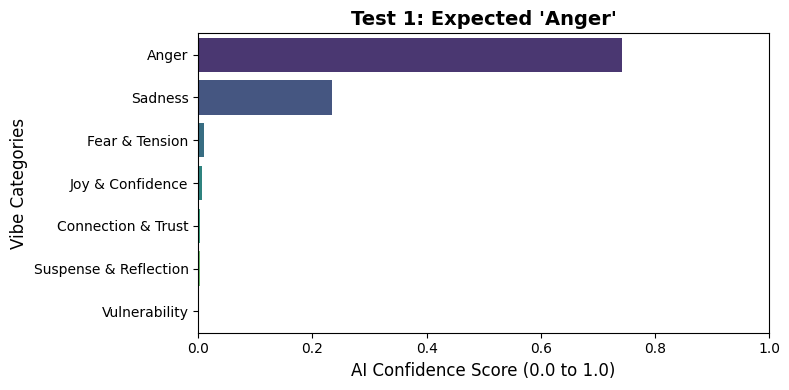

------------------------------------------------------------


/tmp/ipykernel_55/339960831.py:75: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='score', y='label', data=df, palette='viridis')


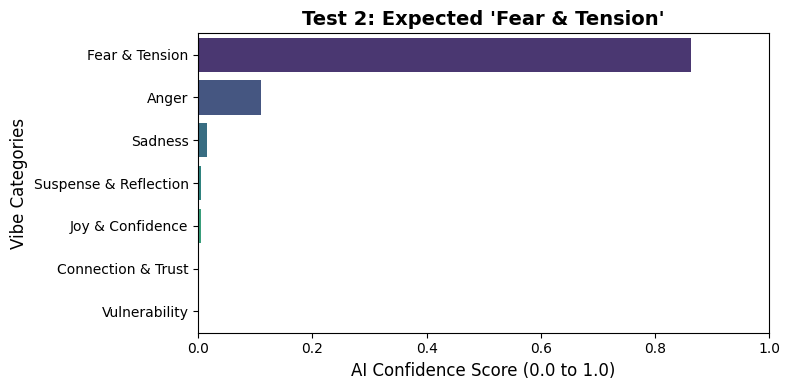

------------------------------------------------------------


/tmp/ipykernel_55/339960831.py:75: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='score', y='label', data=df, palette='viridis')


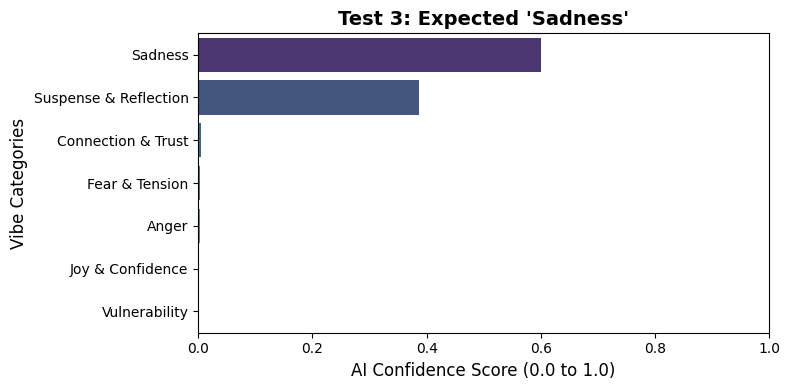

------------------------------------------------------------


/tmp/ipykernel_55/339960831.py:75: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='score', y='label', data=df, palette='viridis')


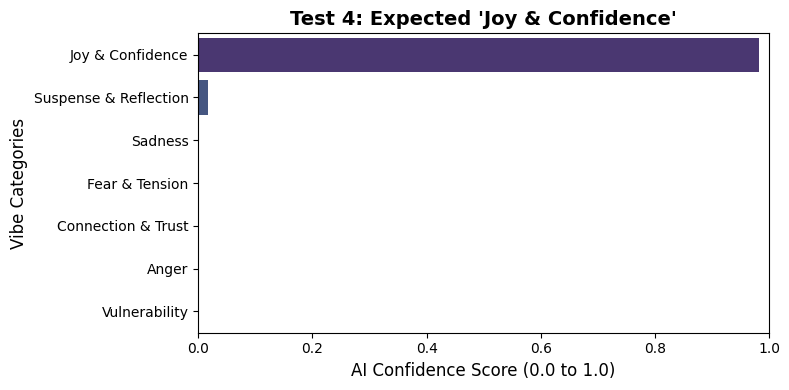

------------------------------------------------------------


/tmp/ipykernel_55/339960831.py:75: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='score', y='label', data=df, palette='viridis')


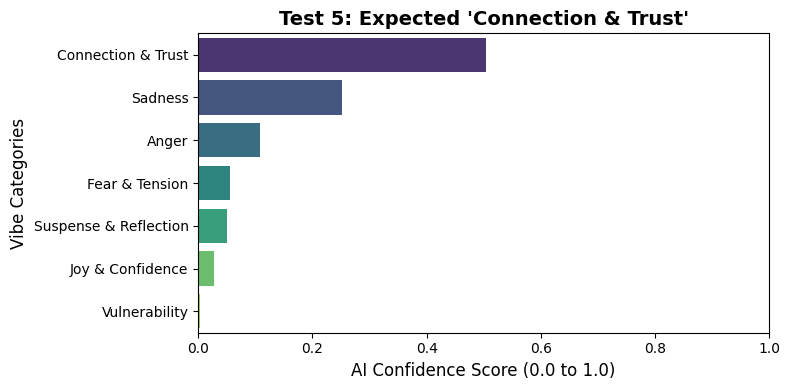

------------------------------------------------------------


/tmp/ipykernel_55/339960831.py:75: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='score', y='label', data=df, palette='viridis')


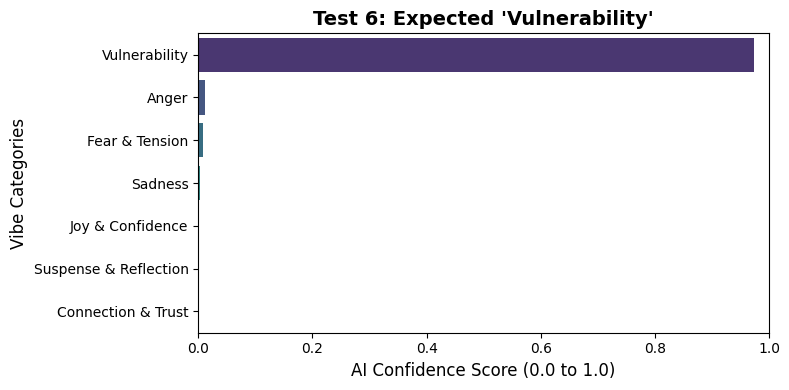

------------------------------------------------------------


/tmp/ipykernel_55/339960831.py:75: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='score', y='label', data=df, palette='viridis')


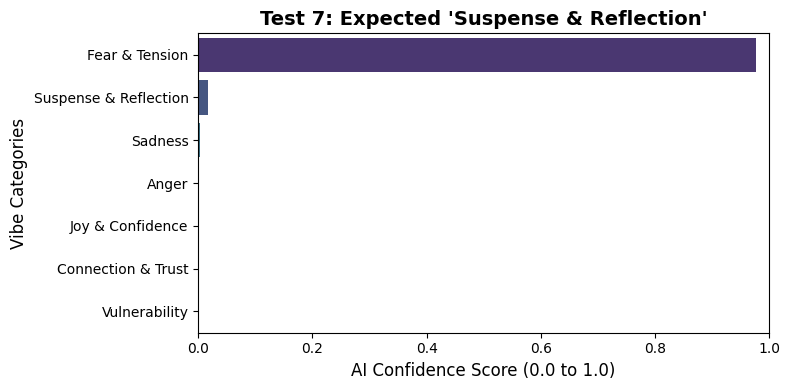

------------------------------------------------------------


In [16]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from transformers import pipeline

# 1. Find the exact path to your newly trained, healthy model!
output_dir = "./gpt2_healthy_vibe_model"
checkpoints = [f for f in os.listdir(output_dir) if f.startswith("checkpoint")]
best_checkpoint = os.path.join(output_dir, sorted(checkpoints, key=lambda x: int(x.split("-")[-1]))[-1])

# 2. Load the AI brain (CRITICAL: top_k=None is required for the graphs!)
print("Loading the AI brain for Brain Scans...")
emotion_classifier_all = pipeline(
    "text-classification", 
    model=best_checkpoint, 
    truncation=True, 
    max_length=160,
    top_k=None # This forces the AI to give us all 7 scores!
)
print("Brain loaded! Generating graphs...\n")

# 3. Your manual test suite
official_test_cases = [
    {
        "expected_vibe": "Anger",
        "situation": "A customer is complaining about a broken product they just bought.",
        "dialogue": "I literally just took this out of the box and it is already shattered. I want a refund right now."
    },
    {
        "expected_vibe": "Fear & Tension",
        "situation": "Someone is trapped in a stalled elevator during a power outage.",
        "dialogue": "The lights just went out and the emergency button isn't working. We need to get out of here!"
    },
    {
        "expected_vibe": "Sadness",
        "situation": "A person is talking about losing their childhood pet.",
        "dialogue": "The house feels so empty without him running to the door every time I come home."
    },
    {
        "expected_vibe": "Joy & Confidence",
        "situation": "A student finding out they passed their final engineering project.",
        "dialogue": "I can't believe we actually got an A! All those sleepless nights coding finally paid off."
    },
    {
        "expected_vibe": "Connection & Trust",
        "situation": "Two friends talking after a long period apart.",
        "dialogue": "No matter how much time passes, I know I can always count on you to have my back."
    },
    {
        "expected_vibe": "Vulnerability",
        "situation": "Someone admitting they made a mistake at work.",
        "dialogue": "I messed up the presentation. I was so nervous that I completely forgot my talking points, and I feel terrible about it."
    },
    {
        "expected_vibe": "Suspense & Reflection",
        "situation": "A detective thinking about an unsolved case.",
        "dialogue": "Every piece of evidence points to him, but something just isn't adding up. I am missing something right in front of me."
    }
]

# 4. Generate the Brain Scan Graphs!
for i, test in enumerate(official_test_cases):
    combined_quote = f"Situation: {test['situation']} Dialogue: {test['dialogue']}"
    
    # Get the math for all 7 buckets
    results = emotion_classifier_all(combined_quote)
    
    # Convert to a clean table and sort highest to lowest
    df = pd.DataFrame(results[0])
    df = df.sort_values(by='score', ascending=False)
    
    # Draw the Bar Chart
    plt.figure(figsize=(8, 4))
    sns.barplot(x='score', y='label', data=df, palette='viridis')
    
    # Add Titles and Labels
    plt.title(f"Test {i+1}: Expected '{test['expected_vibe']}'", fontsize=14, fontweight='bold')
    plt.xlabel('AI Confidence Score (0.0 to 1.0)', fontsize=12)
    plt.ylabel('Vibe Categories', fontsize=12)
    plt.xlim(0, 1) # Lock the bottom axis so all charts are on the same scale
    
    # Show the beautiful graph
    plt.tight_layout()
    plt.show()
    print("-" * 60)

In [15]:
import os
import shutil
from IPython.display import FileLink

# 1. Automatically find the absolute smartest checkpoint in your healthy model folder
output_dir = "./gpt2_healthy_vibe_model"
checkpoints = [f for f in os.listdir(output_dir) if f.startswith("checkpoint")]
best_checkpoint = os.path.join(output_dir, sorted(checkpoints, key=lambda x: int(x.split("-")[-1]))[-1])

# 2. Give the zip file a great name
zip_name = "gpt2_healthy_model_final"

print(f"Zipping your perfectly tuned AI from: {best_checkpoint}...")

# 3. Zip just that single folder
shutil.make_archive(zip_name, 'zip', best_checkpoint)

# 4. Create the download link
print("Done! Click the link below to download your computer engineering masterpiece:")
display(FileLink(f"{zip_name}.zip"))

Zipping your perfectly tuned AI from: ./gpt2_healthy_vibe_model/checkpoint-7188...
Done! Click the link below to download your computer engineering masterpiece:


/kaggle/working/gpt2_healthy_model_final.zip